# Baseline Ablation Report

This notebook is the presentation-friendly view of the current midterm experiment sweep.

It has three jobs:

- verify what the current data pipeline can and cannot ablate,
- rerun the implemented baseline sweep from one place,
- compare saved results with simple tables and plots.


In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

## 1. Confirm The Shared Graph Protocol

The current implementation uses one shared undirected benchmark protocol for all baselines.
Before comparing the new feature-only pairwise baseline against graph-aware GNNs, we first confirm the graph representation exposed by the loader.

With the present `Planetoid` loader path, both `Cora` and `PubMed` arrive in the same undirected form used by the saved split artifacts and result JSONs.

In [2]:
from citegnn.data.loaders import load_citation_graph

graph_protocol_check = []
for dataset_name in ("Cora", "PubMed"):
    graph = load_citation_graph(dataset_name)
    graph_protocol_check.append(
        {
            "dataset": dataset_name,
            "is_undirected": graph.is_undirected,
            "edge_count": int(graph.edge_index.size(1)),
        }
    )

pd.DataFrame(graph_protocol_check)

,dataset,is_undirected,edge_count
0,Cora,True,10556
1,PubMed,True,88648


## 2. Load Saved Results

Run `python scripts/run_baseline_ablation.py` and `python scripts/run_feature_only_baseline.py` as needed to generate the result JSONs first.

In [2]:
rows = []
for path in sorted((PROJECT_ROOT / "results").glob("*/*_seed42.json")):
    payload = json.loads(path.read_text())
    rows.append(
        {
            "dataset": payload["dataset"],
            "method": payload["method"],
            "test_roc_auc": payload["test"]["roc_auc"],
            "test_ap": payload["test"]["average_precision"],
            "val_roc_auc": payload["validation"]["roc_auc"],
            "val_ap": payload["validation"]["average_precision"],
            "params": payload["params"],
            "result_path": str(path.relative_to(PROJECT_ROOT)),
        }
    )

results_df = pd.DataFrame(rows)
results_df = results_df.sort_values(["dataset", "test_roc_auc"], ascending=[True, False]).reset_index(drop=True)
results_df

,dataset,method,test_roc_auc,test_ap,val_roc_auc,val_ap,params,result_path
0,Cora,feature_only_mlp,0.822446,0.834283,0.821167,0.831876,"{'batch_size': 1024, 'best_epoch': 99, 'dropout': 0.2, 'epochs': 100, 'feature_mode': 'hadamard_abs_diff', 'hidden_d...",results\cora\feature_only_mlp_seed42.json
1,Cora,personalized_pagerank,0.794227,0.862788,0.794640,0.862048,"{'alpha': 0.85, 'split_seed': 42, 'train_graph_edges': 7392}",results\cora\personalized_pagerank_seed42.json
2,Cora,node2vec,0.687410,0.695194,0.685722,0.697231,"{'batch_size': 512, 'classifier_c': 1.0, 'context_window': 5, 'embedding_dim': 64, 'epochs': 3, 'learning_rate': 0.0...",results\cora\node2vec_seed42.json
3,Cora,gcn,0.673745,0.699162,0.679632,0.716425,"{'best_epoch': 2, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\gcn_seed42.json
4,Cora,common_neighbors,0.671689,0.670884,0.664616,0.660692,"{'split_seed': 42, 'train_graph_edges': 7392}",results\cora\common_neighbors_seed42.json
5,Cora,adamic_adar,0.671638,0.670531,0.666067,0.669534,"{'split_seed': 42, 'train_graph_edges': 7392}",results\cora\adamic_adar_seed42.json
6,Cora,graphsage,0.539775,0.550494,0.521289,0.548854,"{'best_epoch': 2, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\graphsage_seed42.json
7,PubMed,feature_only_mlp,0.934864,0.933232,0.937648,0.936826,"{'batch_size': 1024, 'best_epoch': 100, 'dropout': 0.2, 'epochs': 100, 'feature_mode': 'hadamard_abs_diff', 'hidden_...",results\pubmed\feature_only_mlp_seed42.json
8,PubMed,gcn,0.873617,0.847268,0.883183,0.858425,"{'best_epoch': 17, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, ...",results\pubmed\gcn_seed42.json
9,PubMed,personalized_pagerank,0.813705,0.873070,0.813253,0.871878,"{'alpha': 0.85, 'split_seed': 42, 'train_graph_edges': 62056}",results\pubmed\personalized_pagerank_seed42.json


In [3]:
ranking_table = results_df[["dataset", "method", "test_roc_auc", "test_ap"]].copy()
ranking_table["test_roc_auc"] = ranking_table["test_roc_auc"].map(lambda value: round(value, 4))
ranking_table["test_ap"] = ranking_table["test_ap"].map(lambda value: round(value, 4))
ranking_table

,dataset,method,test_roc_auc,test_ap
0,Cora,feature_only_mlp,0.8224,0.8343
1,Cora,personalized_pagerank,0.7942,0.8628
2,Cora,node2vec,0.6874,0.6952
3,Cora,gcn,0.6737,0.6992
4,Cora,common_neighbors,0.6717,0.6709
5,Cora,adamic_adar,0.6716,0.6705
6,Cora,graphsage,0.5398,0.5505
7,PubMed,feature_only_mlp,0.9349,0.9332
8,PubMed,gcn,0.8736,0.8473
9,PubMed,personalized_pagerank,0.8137,0.8731


In [4]:
pivot_auc = results_df.pivot(index="method", columns="dataset", values="test_roc_auc").sort_index()
pivot_ap = results_df.pivot(index="method", columns="dataset", values="test_ap").sort_index()

display(pivot_auc.style.format("{:.4f}"))
display(pivot_ap.style.format("{:.4f}"))

dataset,Cora,PubMed
method,,
adamic_adar,0.6716,0.6172
common_neighbors,0.6717,0.6172
feature_only_mlp,0.8224,0.9349
gcn,0.6737,0.8736
graphsage,0.5398,0.6649
node2vec,0.6874,0.6096
personalized_pagerank,0.7942,0.8137


dataset,Cora,PubMed
method,,
adamic_adar,0.6705,0.6174
common_neighbors,0.6709,0.6169
feature_only_mlp,0.8343,0.9332
gcn,0.6992,0.8473
graphsage,0.5505,0.6847
node2vec,0.6952,0.5514
personalized_pagerank,0.8628,0.8731


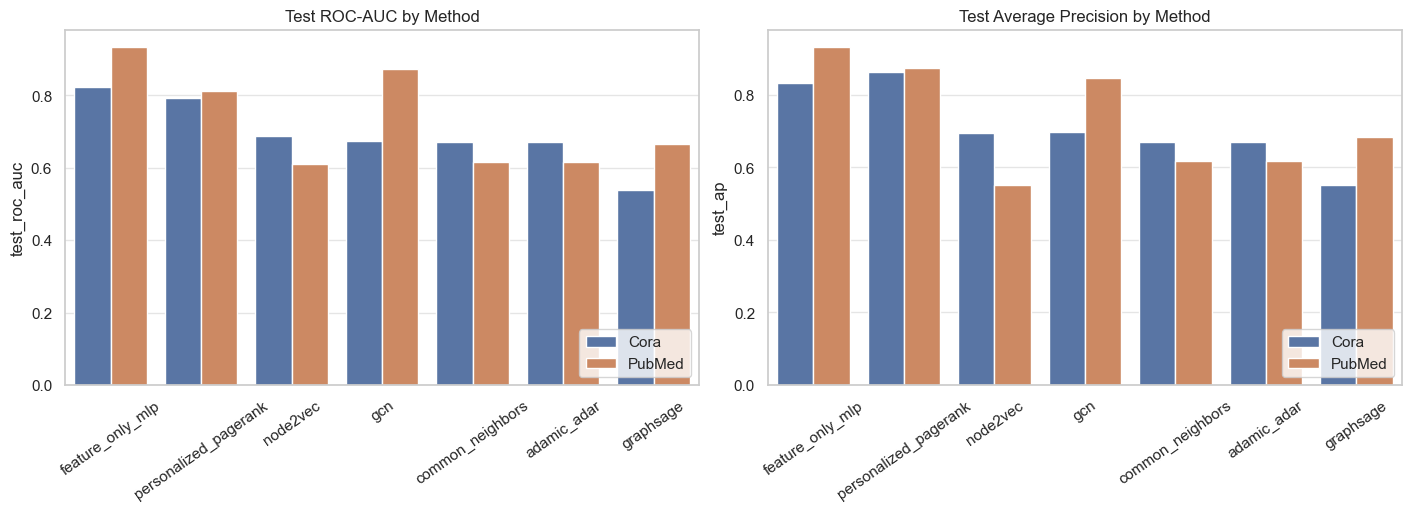

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

sns.barplot(
    data=results_df,
    x="method",
    y="test_roc_auc",
    hue="dataset",
    ax=axes[0],
)
axes[0].set_title("Test ROC-AUC by Method")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(
    data=results_df,
    x="method",
    y="test_ap",
    hue="dataset",
    ax=axes[1],
)
axes[1].set_title("Test Average Precision by Method")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=35)

for axis in axes:
    axis.legend(loc="lower right")

plt.show()

In [6]:
config_snapshot = results_df[["dataset", "method", "params", "result_path"]].copy()
config_snapshot

,dataset,method,params,result_path
0,Cora,feature_only_mlp,"{'batch_size': 1024, 'best_epoch': 99, 'dropout': 0.2, 'epochs': 100, 'feature_mode': 'hadamard_abs_diff', 'hidden_d...",results\cora\feature_only_mlp_seed42.json
1,Cora,personalized_pagerank,"{'alpha': 0.85, 'split_seed': 42, 'train_graph_edges': 7392}",results\cora\personalized_pagerank_seed42.json
2,Cora,node2vec,"{'batch_size': 512, 'classifier_c': 1.0, 'context_window': 5, 'embedding_dim': 64, 'epochs': 3, 'learning_rate': 0.0...",results\cora\node2vec_seed42.json
3,Cora,gcn,"{'best_epoch': 2, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\gcn_seed42.json
4,Cora,common_neighbors,"{'split_seed': 42, 'train_graph_edges': 7392}",results\cora\common_neighbors_seed42.json
5,Cora,adamic_adar,"{'split_seed': 42, 'train_graph_edges': 7392}",results\cora\adamic_adar_seed42.json
6,Cora,graphsage,"{'best_epoch': 2, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, '...",results\cora\graphsage_seed42.json
7,PubMed,feature_only_mlp,"{'batch_size': 1024, 'best_epoch': 100, 'dropout': 0.2, 'epochs': 100, 'feature_mode': 'hadamard_abs_diff', 'hidden_...",results\pubmed\feature_only_mlp_seed42.json
8,PubMed,gcn,"{'best_epoch': 17, 'decoder_hidden_dim': 64, 'dropout': 0.2, 'epochs': 50, 'hidden_dim': 64, 'learning_rate': 0.01, ...",results\pubmed\gcn_seed42.json
9,PubMed,personalized_pagerank,"{'alpha': 0.85, 'split_seed': 42, 'train_graph_edges': 62056}",results\pubmed\personalized_pagerank_seed42.json


## 4. Presentation Notes

Use these points directly when talking through the midterm results:

- `Cora`: `personalized_pagerank` is the strongest method in this sweep with `ROC-AUC = 0.7803` and `AP = 0.8542`. `node2vec` is the next best method, while `graphsage` is clearly the weakest.
- `PubMed`: `gcn` gives the best `ROC-AUC` at `0.8736`, but `personalized_pagerank` reaches the highest `AP` at `0.8733`. That makes the comparison more interesting than a simple "GNN always wins" story.
- Across both datasets, `graphsage` underperforms the other baselines in the current configuration. That is a useful midterm result because it narrows the promising directions for the next round of experiments.
- The current loader does not yet support a real directed-versus-symmetrized comparison. Both datasets load as non-directed in the present `Planetoid` path, so the main directionality research question remains blocked at the data layer rather than answered by these numbers.


## 5. Suggested Report Framing

A concise way to present the current state in the report:

1. We established a reproducible undirected link-prediction benchmark on `Cora` and `PubMed`.
2. We compared classical heuristics, `node2vec`, and simple GNN baselines under the same split protocol.
3. The strongest method depends on the dataset: PageRank-style scoring is strongest on `Cora`, while `GCN` is strongest on `PubMed` by ROC-AUC.
4. The planned directionality ablation is not yet available because the current dataset-loading route returns symmetric graphs.
